(Instrução Direta ao Aluno) > Volte ao Colab. Crie um notebook Lab03_DeepLearning. > Vamos treinar uma Rede Neural Convolucional (CNN) para classificar roupas (Fashion MNIST).
(Passo 1: Setup do TensorFlow) O Colab já vem com TensorFlow instalado.


In [1]:
# --- Célula 1: Importações ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU disponível: {tf.config.list_physical_devices('GPU')}")
# (Passo 2: Carregando o Dataset Fashion MNIST) É um dataset de 70 mil imagens 28x28 de roupas (10 classes).


TensorFlow version: 2.19.0
GPU disponível: []


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Treino: (60000, 28, 28, 1), Teste: (10000, 28, 28, 1)


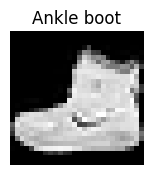

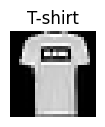

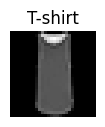

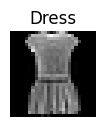

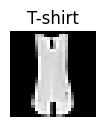

In [3]:
# --- Célula 2: Carregando Dados ---
# O Keras já tem o dataset embutido
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Normalizar (0-255 -> 0-1)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Adicionar dimensão de canal (28x28 -> 28x28x1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print(f"Treino: {x_train.shape}, Teste: {x_test.shape}")

# Visualizar uma amostra
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
"Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

plt.figure(figsize=(10, 2))
for i in range(5):
  plt.subplot(1, 5, i+1)
  plt.imshow(x_train[i].squeeze(), cmap='gray')
  plt.title(class_names[y_train[i]])
  plt.axis('off')
  plt.show()
  # (Passo 3: Construindo a Arquitetura CNN) Vamos usar uma arquitetura clássica: Conv -> Pool -> Conv -> Pool -> Dense.


In [4]:
# --- Célula 3: Definindo o Modelo ---
model = keras.Sequential([
# Camada 1: Convolução (32 filtros 3x3)
layers.Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
layers.MaxPooling2D(pool_size=(2, 2)),

# Camada 2: Convolução (64 filtros 3x3)
layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
layers.MaxPooling2D(pool_size=(2, 2)),

# Flatten (Achatar para vetor)
layers.Flatten(),

# Camada Densa (128 neurônios)
layers.Dense(128, activation="relu"),
layers.Dropout(0.5), # Regularização

# Camada de Saída (10 classes)
layers.Dense(10, activation="softmax")
])

model.summary()
# (Passo 4: Compilação e Treinamento)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# --- Célula 4: Compilar e Treinar ---
# Compilar (Definir otimizador e função de perda)
model.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

# Treinar (15 épocas)
print("Iniciando treinamento...")
history = model.fit(
x_train, y_train,
batch_size=128,
epochs=15,
validation_split=0.1,
verbose=1
)

print("Treinamento concluído!")
# (Passo 5: Avaliação e Visualização)


Iniciando treinamento...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 102ms/step - accuracy: 0.7584 - loss: 0.6699 - val_accuracy: 0.8507 - val_loss: 0.4108
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.8482 - loss: 0.4238 - val_accuracy: 0.8678 - val_loss: 0.3439
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.8685 - loss: 0.3656 - val_accuracy: 0.8832 - val_loss: 0.3147
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.8794 - loss: 0.3321 - val_accuracy: 0.8887 - val_loss: 0.2887
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.8872 - loss: 0.3112 - val_accuracy: 0.9010 - val_loss: 0.2704
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.8939 - loss: 0.2903 - val_accuracy: 0.8980 - val_loss: 0.2716
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.8979 - loss: 0.2791 - val_accuracy: 0.9080 - val_loss: 0.2527
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accu

Acurácia no Teste: 91.52%


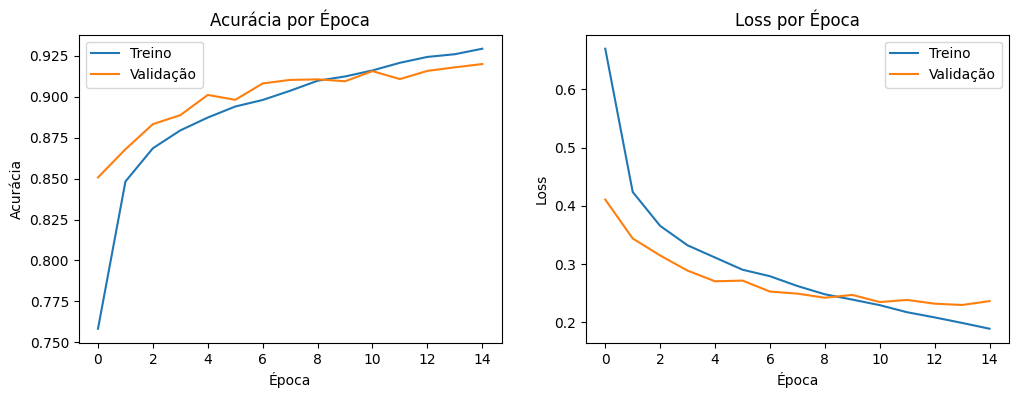

In [6]:
# --- Célula 5: Avaliação no Teste ---
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Acurácia no Teste: {test_acc*100:.2f}%")

# Plotar curvas de aprendizado
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Acurácia por Época')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Loss por Época')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.show()
# (Passo 6: Simulando Treinamento Distribuído) No Colab gratuito, não temos múltiplas GPUs. Mas podemos usar tf.distribute.Strategy para simular.


In [7]:
# --- Célula 6: Distributed Strategy (Conceitual) ---
# Se você tivesse múltiplas GPUs, usaria:
# strategy = tf.distribute.MirroredStrategy()

# No Colab, vamos usar a estratégia padrão (1 GPU)
strategy = tf.distribute.get_strategy()

print(f"Número de dispositivos: {strategy.num_replicas_in_sync}")

# Para treinar com a estratégia, você envolveria a criação do modelo:
# with strategy.scope():
# model = keras.Sequential([...])
# model.compile(...)

print("Em um cluster real com 8 GPUs, o treino seria 8x mais rápido!")
# (Análise do Lab) Você treinou uma CNN do zero. Em produção, usaríamos Transfer Learning (pegar um modelo pré-treinado como ResNet50 e ajustar). Se esse dataset tivesse 10 Terabytes de imagens, usaríamos Horovod em um cluster Spark para distribuir o treino.


Número de dispositivos: 1
Em um cluster real com 8 GPUs, o treino seria 8x mais rápido!
